<a href="https://colab.research.google.com/github/SashaVeremchuk/ITMO-data-analysis/blob/main/3_cluster_dbscan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Дз№3 Кластерный анализ методом DBSCAN
Анализ данных на Python  
ИТМО 2026   
Веремчук Александра

## Постановка задачи
**Описание данных**   
Набор данных "Леденцы" содержит оценки степени согласия респондентов с высказываниями,
отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:   
* V1: Я потребляю леденцы, чтобы освежить дыхание  
* V2: Я потребляю леденцы, чтобы чувствовать себя увереннее  
* V3: Я потребляю леденцы, чтобы освежить полость рта   
* V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту  
* V5: Я потребляю леденцы как заменитель других кондитерских изделий  
* V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого  
* V7: Леденцы помогают мне сконцентрироваться  
* V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать  
* V9: Я потребляю леденцы для того, чтобы облегчить боль в горле  
* V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа  
* V11: Я потребляю леденцы для улучшения самочувствия  

**Задача**  
1. Определить число кластеров и обосновать выбор;   
2. Выполнить кластеризацию;  
3. Предложить содержательную интерпретацию полученных групп.



## Подключение библиотек

In [252]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, fcluster
from matplotlib.collections import LineCollection
from sklearn.neighbors import radius_neighbors_graph

sns.set(style="whitegrid", palette="Set2")

In [253]:
# загрузка данных
df = pd.read_csv("data/lollipops.dat", sep=";")
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [254]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


In [255]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [256]:
for i in df.columns:
  print(f'{i} {df[i].unique()}')

V1 [4 5 3 2]
V2 [5 4 2 3]
V3 [5 4 2 3]
V4 [5 4 2 3]
V5 [3 4 2 5]
V6 [3 4 2 5]
V7 [3 2 4 5]
V8 [3 4 2 5]
V9 [3 4 5 2]
V10 [3 4 5 2]
V11 [3 4 5 2]


**Вывод:**  
Данные нормальные. Пропусков и выбросов нет.   
Нормализовывать данные не нужно, тк данные являются оценочной шкалой, которая уже стандартизирована в значениях от 2 до 5.

## Кластеризация DBSCAN

### Выбор гиперпараметров
Кластеризация основана на плотности кластеров.  
**Гипермараметры:**
  * **`eps`** - радиус окружности,
  * **`min_samples`** - кол-во точек в окружности.

**1. выбиираем `min_samples`.**
Если выбирать при помощи эвристики (формулы), то будем считать, что все признаки независимы, тогда:  
`dim + 1 <= min_samples <= 2 * dim`, dim - размерность данных  
Это [12; 22]. Берём нижнюю границу, тк большое значение может превратить все данные в шум.  

**НО стоит посмотреть на матрицу корреляции признаков.**

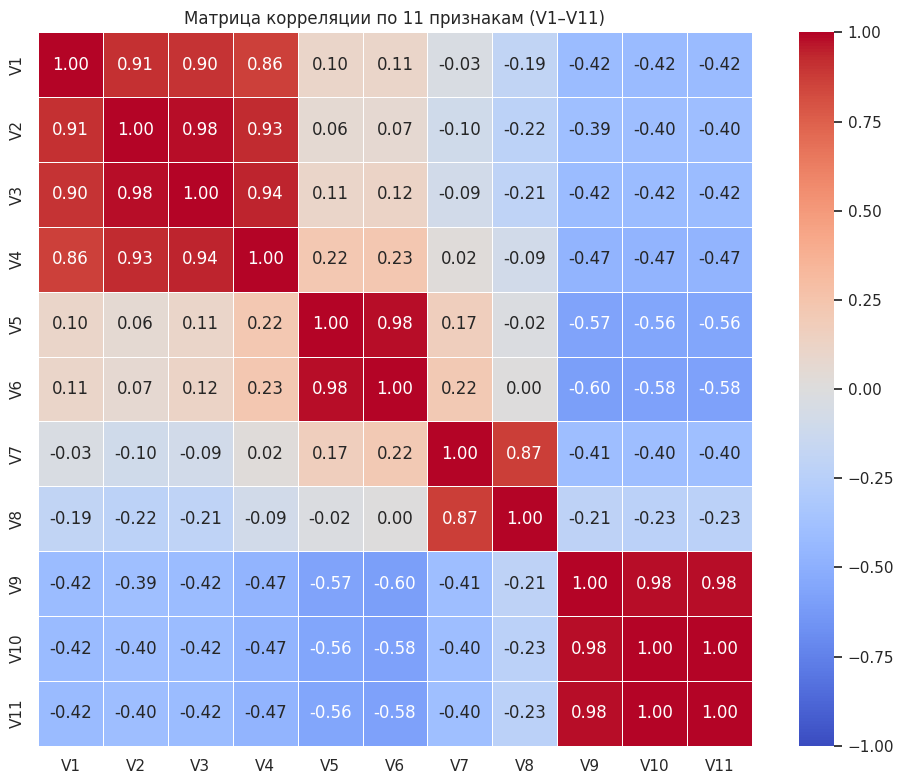

In [257]:
features = df.columns
corr_matrix = df[features].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Матрица корреляции по 11 признакам (V1–V11)")
plt.tight_layout()
plt.show()

Видно, что
* признаки `V1`, `V2`, `V3`, `V4` - коррелируют,  
* признаки `V5`, `V6` - коррелируют,  
* признаки `V7`, `V8` - коррелируют,   
* признаки `V9`, `V10`, `V11` - коррелируют.   
Значит **`min_samples` = 4**

In [258]:
MIN_SAMPLES = 4

**2. `eps` выбираем при помощи k-ближайшего соседа. или при помощи сетки параметров**  
Строим отсортированые расстояния до k соседа при `k = min_samples - 1`, что равно 3.  
* Если плотность высокая, то расстояния будут маленькими.  
* Если плотность низкая, то расстояния будут большими.   

Точка перегиба, когда маленькие расстояния меняются на большие, и будет равна **`eps`**.  

Колено кривой 4-расстояний: 0.000


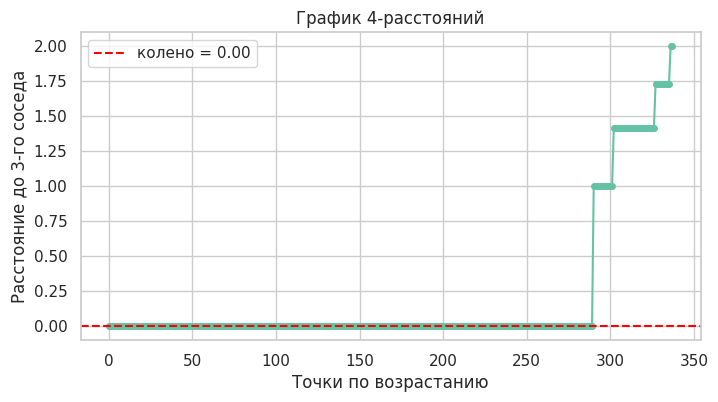

In [259]:
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(df).kneighbors(df)
k_dist = np.sort(dist[:, -1])
idx = np.arange(len(k_dist))
chord = k_dist[0] + (k_dist[-1] - k_dist[0]) * idx / idx[-1]
knee = k_dist[np.argmax(chord - k_dist)]
print(f"Колено кривой 4-расстояний: {knee:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(idx, k_dist, "o-", ms=4)
plt.axhline(knee, ls="--", color="red", label=f"колено = {knee:.2f}")
plt.title("График 4-расстояний")
plt.xlabel("Точки по возрастанию")
plt.ylabel("Расстояние до 3-го соседа")
plt.legend()
plt.show()

Тк у нас много одинаковых значений до резкий скачок был зафиксирован при 0, поэтому для определения **`eps`** воспользуемся **перебором сетки параметров**.

In [260]:
rows = []
for min_samples in [3, 4, 5]:
    for eps in np.round(np.arange(1.0, 2.2, 0.1), 2):
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(df)
        n_clusters = len(set(labels) - {-1})
        n_noise = (labels == -1).sum()
        mask = labels != -1
        sil = np.nan if len(set(labels[mask])) < 2 else silhouette_score(df[mask], labels[mask])

        rows.append({"eps": eps, "min_samples": min_samples,
                     "n_clusters": n_clusters, "n_noise": n_noise,
                     "silhouette": sil})
grid = pd.DataFrame(rows)
pivot = grid.pivot(index="eps", columns="min_samples", values=["n_clusters", "n_noise", "silhouette"])
display(pivot.round(3))

n_clusters            n_noise             silhouette              
min_samples          3     4    5       3     4     5          3      4      5
eps                                                                           
1.0               16.0  11.0  9.0    21.0  36.0  44.0      0.865  0.901  0.898
1.1               16.0  11.0  9.0    21.0  36.0  44.0      0.865  0.901  0.898
1.2               16.0  11.0  9.0    21.0  36.0  44.0      0.865  0.901  0.898
1.3               16.0  11.0  9.0    21.0  36.0  44.0      0.865  0.901  0.898
1.4               16.0  11.0  9.0    21.0  36.0  44.0      0.865  0.901  0.898
1.5               12.0  10.0  8.0     5.0  11.0  19.0      0.729  0.783  0.786
1.6               12.0  10.0  8.0     5.0  11.0  19.0      0.729  0.783  0.786
1.7               12.0  10.0  8.0     5.0  11.0  19.0      0.729  0.783  0.786
1.8                5.0   5.0  4.0     2.0   2.0   6.0      0.681  0.681  0.737
1.9                5.0   5.0  4.0     2.0   2.0   6.0      0.681  0.681  0.737
2.0                4.0   4.0  3.0     0.0   0.0   4.0      0.560  0.560  0.620
2.1                4.0   4.0  3.0     0.0   0.0   4.0      0.560  0.560  0.620
2.2                4.0   4.0  3.0     0.0   0.0   4.0      0.560  0.560  0.620

Выбираем **`eps` = 2.0**, тк:   
* Если выберем `eps` = 1.2, то это слишком жёсткое ограничение, чуть больше корня из 1), тк тогда мы допускаем различие лишь в 1 вопросе из 11 на 1 балл.
* Есои выберем`eps` = 1.45, то допускаем различие на 1 балл по 3 вопросам из 11.  
* Если `eps` = 2.0, то допускаем различие на 1 балл в 4 вопросах из 11. Этот вариант оптимален, тк такое допущение разумно (люди просто чуть менее согласны), у нас появляется 4 кластера, что оптимально, если смотреть на метод Локтя в иерархическом кластерном анализе и у нас нет шума.

### Итоги кластеризации

In [261]:
EPS = 2.0
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(df)
labels_db = db.labels_

print(f"Кластеров: {len(set(labels_db) - {-1})}")
print(f"Шумовых точек: {(labels_db == -1).sum()}")

table = df.assign(cluster=labels_db).groupby("cluster").mean().round(2)
table.insert(0, "size", pd.Series(labels_db).value_counts().sort_index().values)

display(table)

Кластеров: 4
Шумовых точек: 0


,size,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,,
0,110,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
1,104,2.86,2.79,2.72,2.57,2.63,2.61,2.78,2.91,4.95,4.82,4.87
2,4,2.00,4.00,4.00,4.00,2.00,2.00,2.00,3.00,5.00,4.75,4.75
3,120,3.00,2.98,2.98,2.96,3.90,3.92,3.94,3.90,2.88,2.88,2.88


### График кластеров

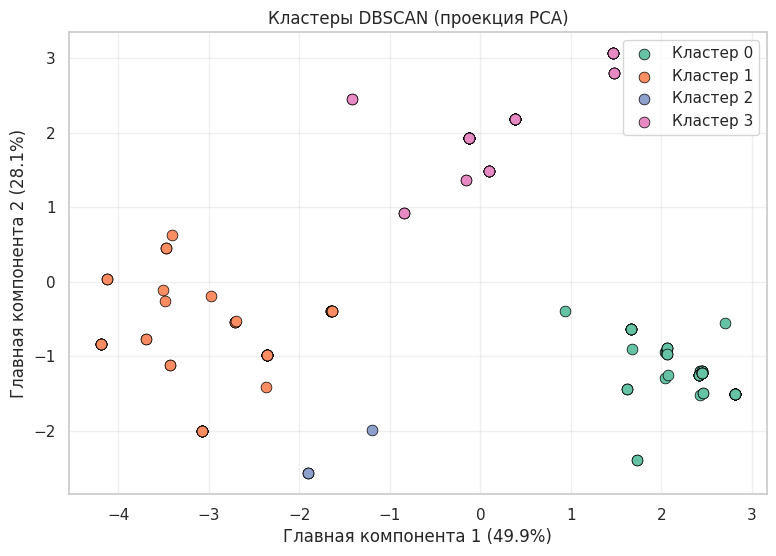

In [262]:
pca = PCA(n_components=2, random_state=42)
xy_pca = pca.fit_transform(df)
var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(9, 6))

for k in np.unique(labels_db):
    mask = labels_db == k
    ax.scatter(*xy[mask].T, s=60, edgecolor="k", linewidth=0.5, label=f"Кластер {k}")

ax.set_title("Кластеры DBSCAN (проекция PCA)")
ax.set_xlabel(f"Главная компонента 1 ({var[0]:.1f}%)")
ax.set_ylabel(f"Главная компонента 2 ({var[1]:.1f}%)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

### График соседей

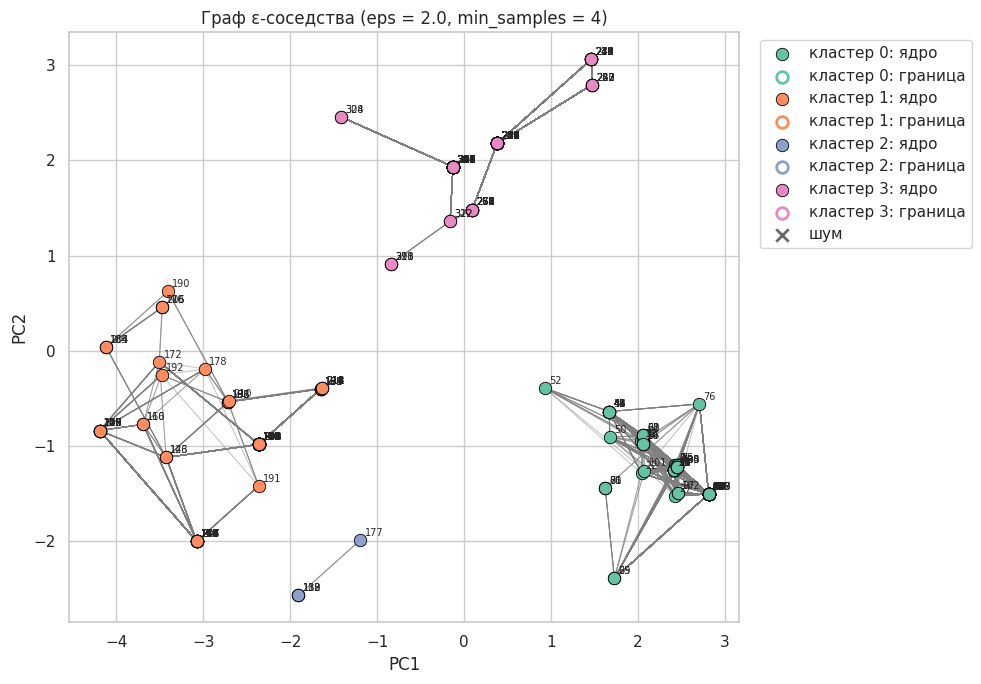

In [263]:
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(df)
core = np.zeros(len(df), dtype=bool)
core[db.core_sample_indices_] = True
graph = radius_neighbors_graph(df, EPS).tocoo()
edges = [(xy_pca[i], xy_pca[j]) for i, j in zip(graph.row, graph.col) if i < j and (core[i] or core[j])]
colors = sns.color_palette()

fig, ax = plt.subplots(figsize=(10, 7))
ax.add_collection(LineCollection(edges, colors="grey", linewidths=0.7, alpha=0.5, zorder=1))
for k in sorted(set(labels_db) - {-1}):
    in_k = labels_db == k
    ax.scatter(*xy_pca[in_k & core].T, color=colors[k], s=80, edgecolor="k", linewidth=0.6, zorder=3,
               label=f"кластер {k}: ядро")
    ax.scatter(*xy_pca[in_k & ~core].T, color="white", s=70, edgecolor=colors[k], linewidth=2, zorder=3,
               label=f"кластер {k}: граница")
ax.scatter(*xy_pca[labels_db == -1].T, c="dimgrey", marker="x", s=80, linewidth=2, zorder=3, label="шум")
for (x, y), name, is_noise in zip(xy_pca, names, labels_db == -1):
    ax.annotate(name, (x, y), xytext=(3, 3), textcoords="offset points",
                fontsize=8 if is_noise else 7, fontweight="bold" if is_noise else "normal")
ax.set(title=f"Граф ε-соседства (eps = {EPS}, min_samples = {MIN_SAMPLES})", xlabel="PC1", ylabel="PC2")

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [264]:
table = df.assign(cluster=labels_db + 1).groupby("cluster").mean().round(2)
table.insert(0, "size", pd.Series(labels_db).value_counts().sort_index().values)
display(table)

,size,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,,
1,110,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
2,104,2.86,2.79,2.72,2.57,2.63,2.61,2.78,2.91,4.95,4.82,4.87
3,4,2.00,4.00,4.00,4.00,2.00,2.00,2.00,3.00,5.00,4.75,4.75
4,120,3.00,2.98,2.98,2.96,3.90,3.92,3.94,3.90,2.88,2.88,2.88


## Интерпретация 1

Видно 4 группы:
  1) Освежающие (110)
  2) Медицинские (104)
  3) Лечение и уверенность (4)
  4) Замена сладостям и помощь в концентрации внимания (120)
  3) Для концентрации: V7, V8;

**Выводы:**  
Из-за разной плотности кластеров, DBSCAN выделил другие кластеры, которые сильно отличаются по размеру и сложностью в однозначной интерпретации группы.


## Уменьшение `eps`=1.8   
Чтобы получилось 5 кластеров.

In [265]:
EPS = 1.8
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(df)
labels_db = db.labels_

print(f"Кластеров: {len(set(labels_db) - {-1})}")
print(f"Шумовых точек: {(labels_db == -1).sum()}")

table = df.assign(cluster=labels_db).groupby("cluster").mean().round(2)
table.insert(0, "size", pd.Series(labels_db).value_counts().sort_index().values)

display(table)

Кластеров: 5
Шумовых точек: 2


,size,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,,
-1,2,3.00,2.00,2.00,2.00,2.00,3.00,5.00,5.00,3.00,3.00,3.00
0,110,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
1,104,2.86,2.79,2.72,2.57,2.63,2.61,2.78,2.91,4.95,4.82,4.87
2,4,2.00,4.00,4.00,4.00,2.00,2.00,2.00,3.00,5.00,4.75,4.75
3,61,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
4,57,3.00,3.00,3.00,2.95,2.95,2.95,4.91,4.91,3.00,3.00,3.00


### График соседей для `eps` = 1.8

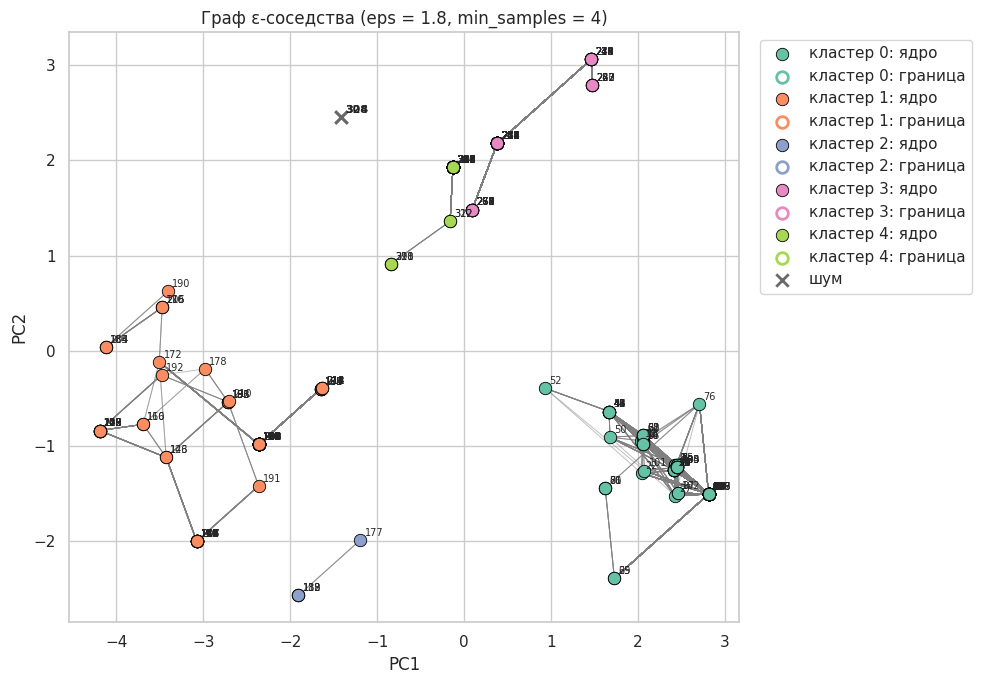

In [266]:
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(df)
core = np.zeros(len(df), dtype=bool)
core[db.core_sample_indices_] = True
graph = radius_neighbors_graph(df, EPS).tocoo()
edges = [(xy_pca[i], xy_pca[j]) for i, j in zip(graph.row, graph.col) if i < j and (core[i] or core[j])]
colors = sns.color_palette()

fig, ax = plt.subplots(figsize=(10, 7))
ax.add_collection(LineCollection(edges, colors="grey", linewidths=0.7, alpha=0.5, zorder=1))
for k in sorted(set(labels_db) - {-1}):
    in_k = labels_db == k
    ax.scatter(*xy_pca[in_k & core].T, color=colors[k], s=80, edgecolor="k", linewidth=0.6, zorder=3,
               label=f"кластер {k}: ядро")
    ax.scatter(*xy_pca[in_k & ~core].T, color="white", s=70, edgecolor=colors[k], linewidth=2, zorder=3,
               label=f"кластер {k}: граница")
ax.scatter(*xy_pca[labels_db == -1].T, c="dimgrey", marker="x", s=80, linewidth=2, zorder=3, label="шум")
for (x, y), name, is_noise in zip(xy_pca, names, labels_db == -1):
    ax.annotate(name, (x, y), xytext=(3, 3), textcoords="offset points",
                fontsize=8 if is_noise else 7, fontweight="bold" if is_noise else "normal")
ax.set(title=f"Граф ε-соседства (eps = {EPS}, min_samples = {MIN_SAMPLES})", xlabel="PC1", ylabel="PC2")

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Интерпретация 2  
При **`eps` = 1.8** разбиение получилось точнее, но были найден **2 шумовые точки**.   
1) Освежающие (110),
2) Медицинские (104),  
3) Лечение и уверенность (4),
4) Сладкоежки (61),  
5) Для концентрации (57).

## Сравнение методов кластеризации

In [267]:
labels_ward = fcluster(linkage(df, method="ward"), 4, criterion="maxclust")
labels_km = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(df)

mask = labels_db != -1
sil_db = silhouette_score(df[mask], labels_db[mask]) if len(np.unique(labels_db[mask])) >= 2 else np.nan

summary = pd.DataFrame({
    "кластеров": [4, 4, len(set(labels_db) - {-1})],
    "шум": [0, 0, (labels_db == -1).sum()],
    "silhouette": [
        silhouette_score(df, labels_ward),
        silhouette_score(df, labels_km),
        sil_db
    ],
    "ARI с k-means": [
        adjusted_rand_score(labels_ward, labels_km),
        1.0,
        adjusted_rand_score(labels_db, labels_km)
    ],
}, index=["Ward", "k-means", f"DBSCAN eps={EPS}"]).round(3)

display(summary)


,кластеров,шум,silhouette,ARI с k-means
Ward,4,0,0.727,1.000
k-means,4,0,0.727,1.000
DBSCAN eps=1.8,5,2,0.681,0.976


## Выводы:   
В этой задаче DBSCAN справляется хуже, чем другие методы, скорее всего из-за разной плотности кластеров, поэтому стоит использовать HDBSCAN, который не чувствителен к плотности кластеров.  

В этой здаче лучше использовать DBSCAN c **`eps` = 1.8**, **`min_samples` = 4**, в итоге получится **5 кластеров** и **2 выброса**, но группы будут более однородными (легче интерпретировать).
